In [24]:
import polars as pl
import numpy as np
import polars.selectors as sl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sentence_transformers import SentenceTransformer, util 
from itertools import combinations

pl.Config.set_fmt_str_lengths(500)
pl.Config.set_tbl_rows(-1)

polars.config.Config

In [2]:
file_path = Path('../outputs/LLM/glint/risultati_llm_20261114_162646.csv')
df = pl.read_csv(
    file_path,
    separator=',',
    infer_schema_length=None
).drop(
    ['timestamp']
)

df.head(5)

modello,file,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
str,str,str,str,i64,f64,i64,i64
"""LFM2-1.2B""","""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; head of adequate size""","""The photo features a face with eyes slightly closed, improperly spaced above and below the head, and a uniform background, capturing a neutral expression on the head of adequate size.""",30,0.15,91,36
"""LFM2-1.2B""","""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The photo features eyes half-closed, uneven background and lighting, but the face is clear and properly framed despite minor issues. The subject's head is slightly smaller than ideal, and there's a small space below the face.""",36,0.15,92,46
"""LFM2-1.2B""","""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; head slightly small in the frame Good aspects: eyes open; well exposed image; proper space above the head; proper space below the face""","""The face photo shows a non-neutral expression with partial covering, cluttered background, and uneven lighting, but the eyes are open and the lighting is good. The subject's head is slightly smaller than the frame, with proper space above and below the face.""",42,0.17,97,53
"""LFM2-1.2B""","""253241_013447951.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; head slightly small in the frame; slightly improper space above the head Good aspects: no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""The face photo features closed eyes, a slightly smaller head, and proper spacing above the head, with even lighting and a well-exposed image against a uniform background.""",27,0.12,92,34
"""LFM2-1.2B""","""61183_003885109.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven lighting; improper space below the face Good aspects: eyes open; uniform background; well exposed image; head of adequate size; proper space above the head""","""The face photo shows a partial head covering, uneven lighting, and improper space below the face, but the eyes are open, the background is uniform, and the image is well-exposed with adequate head size.""",34,0.14,84,43


In [3]:
models = {k[0]: v for k, v in df.partition_by('modello', as_dict=True).items()}

In [4]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','risposta', 'tempo_s', 'num_parole'].head(5))

--- LFM2-1.2B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The photo features a face with eyes slightly closed, improperly spaced above and below the head, and a uniform background, capturing a neutral expression on the head of adequate size.""",0.15,30
"""69585_004367750.jpg""","""The photo features eyes half-closed, uneven background and lighting, but the face is clear and properly framed despite minor issues. The subject's head is slightly smaller than ideal, and there's a small space below the face.""",0.15,36
"""141548_008381717.jpg""","""The face photo shows a non-neutral expression with partial covering, cluttered background, and uneven lighting, but the eyes are open and the lighting is good. The subject's head is slightly smaller than the frame, with proper space above and below the face.""",0.17,42
"""253241_013447951.jpg""","""The face photo features closed eyes, a slightly smaller head, and proper spacing above the head, with even lighting and a well-exposed image against a uniform background.""",0.12,27
"""61183_003885109.jpg""","""The face photo shows a partial head covering, uneven lighting, and improper space below the face, but the eyes are open, the background is uniform, and the image is well-exposed with adequate head size.""",0.14,34


--- Gemma-3-1B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""Here’s a description: The image features a face with partially closed eyes and an uneven space above the head. The face is framed by a neutral expression and has a uniform background, with adequate lighting illuminating the face.""",0.29,38
"""69585_004367750.jpg""","""Here’s a description: The photo features a face with partially closed eyes and a slightly uneven background. The lighting is uneven, creating a subtle shadow beneath the face. The image is slightly too dark or bright, and the head appears too small in the frame.""",0.28,45
"""141548_008381717.jpg""","""The photo depicts a face with a subtly anxious expression, partially obscured by a dark cloth. The image is slightly uneven in lighting and lacks a clear, neutral background, creating a sense of unease.""",0.21,34
"""253241_013447951.jpg""","""Here’s a description: A portrait shows a face with closed eyes and a small head, framed by a neutral background. The image is well-lit and evenly exposed, creating a balanced and straightforward view.""",0.23,33
"""61183_003885109.jpg""","""Here’s a description: A partially covered face is captured in a photograph, with slightly uneven lighting creating a subtle shadow. The image showcases open eyes and a uniform background, while the head appears adequately sized and positioned above the face.""",0.25,40


--- Qwen3-4B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The photo has a neutral expression, no head covering, uniform background, and even lighting on the face. It is well exposed with a head of adequate size, though there are minor issues with spacing above the head and below the face, and the eyes are partly closed.""",0.54,47
"""69585_004367750.jpg""","""The photo has eyes that are partly closed, slightly uneven background, and uneven lighting. It is slightly too dark or bright, with the head too small and improper space below the face, but it has proper space above the head and no head covering.""",0.48,44
"""141548_008381717.jpg""","""The photo shows clear, open eyes and proper spacing above and below the face. It has a slightly uneven lighting and a cluttered background, but the head is appropriately sized within the frame.""",0.37,33
"""253241_013447951.jpg""","""A passport-style face photo shows a clear, well-exposed image with uniform background and even lighting on the face. The head is properly spaced below the face, though the space above the head is slightly improper.""",0.41,35
"""61183_003885109.jpg""","""The photo shows eyes open, uniform background, and well-exposed image. It has proper space above the head, but includes partial head covering and slightly uneven lighting.""",0.32,26


... (4 outputs left out)

--- Qwen3-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The passport-style face photo shows eyes partly closed with a neutral expression. The head is of adequate size, with even lighting on the face and a uniform background.""",0.53,28
"""69585_004367750.jpg""","""The face photo shows eyes partly closed with slightly uneven lighting and a dark image. The background is uneven, the head appears too small, and there is improper space below the face, though proper space is maintained above the head.""",0.69,40
"""141548_008381717.jpg""","""The passport-style face photo shows a non-neutral expression and a partial head covering. The background is cluttered and uneven, with slightly uneven lighting and a head that appears slightly small in the frame.""",0.6,33
"""253241_013447951.jpg""","""The subject has eyes closed or mostly closed. The head appears slightly small in the frame with improper space above it, but the face is well exposed with even lighting and proper space below. No head covering is present, and the background is uniform.""",0.75,44
"""61183_003885109.jpg""","""The passport-style face photo shows a person with eyes open and a uniform background. The image is well exposed, with the head of adequate size and proper space above the head, though there is a partial head covering, slightly uneven lighting, and improper space below the face.""",0.81,47


--- Llama-3.1-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The passport-style face photo shows a neutral expression with even lighting on the face, well-exposed image, and a uniform background. However, it has some issues, including partly closed eyes and improper spacing above and below the face.""",0.73,37
"""69585_004367750.jpg""","""The passport-style face photo shows a person with their eyes partly closed, against a slightly uneven background with uneven lighting. The image is either too dark or too bright, and the head is too small in the frame.""",0.64,38
"""141548_008381717.jpg""","""The passport-style face photo shows a person with a clearly non-neutral expression, partially covered head, and cluttered background. The image is well-exposed, but has uneven lighting and the head is slightly small in the frame.""",0.67,35
"""253241_013447951.jpg""","""The face photo shows a person with their eyes mostly closed, positioned in a frame that slightly emphasizes their head's size. The image has a uniform background, even lighting, and proper exposure.""",0.58,32
"""61183_003885109.jpg""","""The passport-style face photo shows a well-exposed image of a person with their eyes open, against a uniform background, with their head of adequate size and proper space above the head. However, it has some issues, including partial head covering, slightly uneven lighting, and improper space below the face.""",0.87,49


In [5]:
target = ['num_parole', 'tempo_s', 'prompt_tokens', 'completion_tokens']

for model, df_sub in models.items():
    print(f"=== Statistiche per il modello: {model} ===")
    
    display(df_sub[target].describe())
    print("\n")

=== Statistiche per il modello: LFM2-1.2B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",31.9374,0.13465,91.2902,40.5314
"""std""",5.371113,0.019917,3.653526,6.733653
"""min""",16.0,0.08,84.0,24.0
"""25%""",28.0,0.12,89.0,36.0
"""50%""",32.0,0.13,91.0,40.0
"""75%""",35.0,0.15,94.0,45.0
"""max""",96.0,0.38,105.0,125.0




=== Statistiche per il modello: Gemma-3-1B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",35.1874,0.229712,91.1074,45.4346
"""std""",3.794781,0.021772,3.451007,4.662196
"""min""",22.0,0.15,84.0,28.0
"""25%""",33.0,0.22,89.0,42.0
"""50%""",35.0,0.23,91.0,45.0
"""75%""",38.0,0.24,93.0,48.0
"""max""",50.0,0.32,104.0,66.0




=== Statistiche per il modello: Qwen3-4B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",34.859,0.390844,92.1396,41.5614
"""std""",5.503124,0.05773,3.464695,6.539632
"""min""",20.0,0.24,85.0,24.0
"""25%""",31.0,0.35,90.0,37.0
"""50%""",35.0,0.39,92.0,42.0
"""75%""",38.0,0.43,94.0,46.0
"""max""",57.0,0.64,105.0,69.0


... (4 outputs left out)



=== Statistiche per il modello: Qwen3-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",43.1338,0.758508,92.1396,51.2604
"""std""",7.800261,0.12889,3.464695,8.994197
"""min""",19.0,0.34,85.0,23.0
"""25%""",38.0,0.68,90.0,46.0
"""50%""",44.0,0.77,92.0,52.0
"""75%""",49.0,0.85,94.0,57.0
"""max""",63.0,1.11,105.0,75.0




=== Statistiche per il modello: Llama-3.1-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",40.4134,0.709528,114.1396,49.1042
"""std""",4.681077,0.074766,3.464695,5.418156
"""min""",27.0,0.48,107.0,32.0
"""25%""",37.0,0.66,112.0,45.0
"""50%""",41.0,0.71,114.0,49.0
"""75%""",44.0,0.76,116.0,53.0
"""max""",58.0,0.97,127.0,68.0


In [6]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','prompt','risposta'].head(5))

--- LFM2-1.2B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; head of adequate size""","""The photo features a face with eyes slightly closed, improperly spaced above and below the head, and a uniform background, capturing a neutral expression on the head of adequate size."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The photo features eyes half-closed, uneven background and lighting, but the face is clear and properly framed despite minor issues. The subject's head is slightly smaller than ideal, and there's a small space below the face."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; head slightly small in the frame Good aspects: eyes open; well exposed image; proper space above the head; proper space below the face""","""The face photo shows a non-neutral expression with partial covering, cluttered background, and uneven lighting, but the eyes are open and the lighting is good. The subject's head is slightly smaller than the frame, with proper space above and below the face."""
"""253241_013447951.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; head slightly small in the frame; slightly improper space above the head Good aspects: no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""The face photo features closed eyes, a slightly smaller head, and proper spacing above the head, with even lighting and a well-exposed image against a uniform background."""
"""61183_003885109.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven lighting; improper space below the face Good aspects: eyes open; uniform background; well exposed image; head of adequate size; proper space above the head""","""The face photo shows a partial head covering, uneven lighting, and improper space below the face, but the eyes are open, the background is uniform, and the image is well-exposed with adequate head size."""


--- Gemma-3-1B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; head of adequate size""","""Here’s a description: The image features a face with partially closed eyes and an uneven space above the head. The face is framed by a neutral expression and has a uniform background, with adequate lighting illuminating the face."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""Here’s a description: The photo features a face with partially closed eyes and a slightly uneven background. The lighting is uneven, creating a subtle shadow beneath the face. The image is slightly too dark or bright, and the head appears too small in the frame."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; head slightly small in the frame Good aspects: eyes open; well exposed image; proper space above the head; proper space below the face""","""The photo depicts a face with a subtly anxious expression, partially obscured by a dark cloth. The image is slightly uneven in lighting and lacks a clear, neutral background, creating a sense of unease."""
"""253241_013447951.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; head slightly small in the frame; slightly improper space above the head Good aspects: no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""Here’s a description: A portrait shows a face with closed eyes and a small head, framed by a neutral background. The image is well-lit and evenly exposed, creating a balanced and straightforward view."""
"""61183_003885109.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven lighting; improper space below the face Good aspects: eyes open; uniform background; well exposed image; head of adequate size; proper space above the head""","""Here’s a description: A partially covered face is captured in a photograph, with slightly uneven lighting creating a subtle shadow. The image showcases open eyes and a uniform background, while the head appears adequately sized and positioned above the face."""


--- Qwen3-4B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; head of adequate size""","""The photo has a neutral expression, no head covering, uniform background, and even lighting on the face. It is well exposed with a head of adequate size, though there are minor issues with spacing above the head and below the face, and the eyes are partly closed."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The photo has eyes that are partly closed, slightly uneven background, and uneven lighting. It is slightly too dark or bright, with the head too small and improper space below the face, but it has proper space above the head and no head covering."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; head slightly small in the frame Good aspects: eyes open; well exposed image; proper space above the head; proper space below the face""","""The photo shows clear, open eyes and proper spacing above and below the face. It has a slightly uneven lighting and a cluttered background, but the head is appropriately sized within the frame."""
"""253241_013447951.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; head slightly small in the frame; slightly improper space above the head Good aspects: no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""A passport-style face photo shows a clear, well-exposed image with uniform background and even lighting on the face. The head is properly spaced below the face, though the space above the head is slightly improper."""
"""61183_003885109.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven lighting; improper space below the face Good aspects: eyes open; uniform background; well exposed image; head of adequate size; proper space above the head""","""The photo shows eyes open, uniform background, and well-exposed image. It has proper space above the head, but includes partial head covering and slightly uneven lighting."""


... (4 outputs left out)

--- Qwen3-8B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; head of adequate size""","""The passport-style face photo shows eyes partly closed with a neutral expression. The head is of adequate size, with even lighting on the face and a uniform background."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The face photo shows eyes partly closed with slightly uneven lighting and a dark image. The background is uneven, the head appears too small, and there is improper space below the face, though proper space is maintained above the head."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; head slightly small in the frame Good aspects: eyes open; well exposed image; proper space above the head; proper space below the face""","""The passport-style face photo shows a non-neutral expression and a partial head covering. The background is cluttered and uneven, with slightly uneven lighting and a head that appears slightly small in the frame."""
"""253241_013447951.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; head slightly small in the frame; slightly improper space above the head Good aspects: no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""The subject has eyes closed or mostly closed. The head appears slightly small in the frame with improper space above it, but the face is well exposed with even lighting and proper space below. No head covering is present, and the background is uniform."""
"""61183_003885109.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven lighting; improper space below the face Good aspects: eyes open; uniform background; well exposed image; head of adequate size; proper space above the head""","""The passport-style face photo shows a person with eyes open and a uniform background. The image is well exposed, with the head of adequate size and proper space above the head, though there is a partial head covering, slightly uneven lighting, and improper space below the face."""


--- Llama-3.1-8B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; head of adequate size""","""The passport-style face photo shows a neutral expression with even lighting on the face, well-exposed image, and a uniform background. However, it has some issues, including partly closed eyes and improper spacing above and below the face."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The passport-style face photo shows a person with their eyes partly closed, against a slightly uneven background with uneven lighting. The image is either too dark or too bright, and the head is too small in the frame."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; head slightly small in the frame Good aspects: eyes open; well exposed image; proper space above the head; proper space below the face""","""The passport-style face photo shows a person with a clearly non-neutral expression, partially covered head, and cluttered background. The image is well-exposed, but has uneven lighting and the head is slightly small in the frame."""
"""253241_013447951.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; head slightly small in the frame; slightly improper space above the head Good aspects: no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""The face photo shows a person with their eyes mostly closed, positioned in a frame that slightly emphasizes their head's size. The image has a uniform background, even lighting, and proper exposure."""
"""61183_003885109.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven lighting; improper space below the face Good aspects: eyes open; uniform background; well exposed image; head of adequate size; proper space above the head""","""The passport-style face photo shows a well-exposed image of a person with their eyes open, against a uniform background, with their head of adequate size and proper space above the head. However, it has some issues, including partial head covering, slightly uneven lighting, and improper space below the face."""


#### DA FARE: 
- TRASFORMARLI IN VETTORI
- CONFRONTARLI
- TOKENIZARLI

In [10]:
# Create a new dict where the key is the model name, and values are the text trasformed into vectors --> from the models dict
embedder_name = 'paraphrase-multilingual-MiniLM-L12-v2'
emb_model = SentenceTransformer(embedder_name)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [14]:
embeddings = {
    nome: emb_model.encode(
        d["risposta"].to_list(),  
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
    for nome, d in models.items()
}

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

In [17]:
models_name = list(embeddings)

similarities = {
    (a,b): (embeddings[a] * embeddings[b]).sum(axis=1)
    for a,b in combinations(models_name,2)
}

M = np.eye(len(models_name))
for i,a in enumerate(models_name):
    for j,b in enumerate(models_name):
        if i < j:
            M[i, j] = M[j, i] = similarities[(a, b)].mean()

mat = pl.DataFrame(M,schema=models_name).with_columns(pl.Series('modello',models_name))

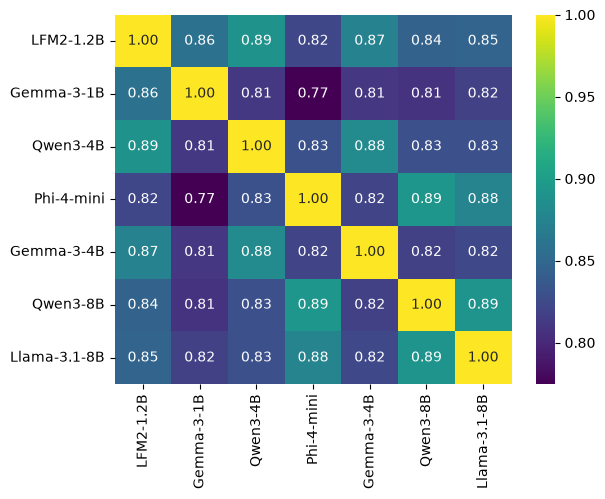

In [20]:
sns.heatmap(M, xticklabels=models_name, yticklabels=models_name, annot=True, fmt=".2f", cmap="viridis")
plt.show()

In [21]:
righe = []
for (a, b), s in similarities.items():
    righe.append({
        "A": a, "B": b,
        "media": s.mean(),
        "p5": np.percentile(s, 5),
        "mediana": np.median(s),
        "p95": np.percentile(s, 95),
    })
confronto = pl.DataFrame(righe).sort("media", descending=True)

In [25]:
confronto

A,B,media,p5,mediana,p95
str,str,f64,f64,f64,f64
"""Phi-4-mini""","""Qwen3-8B""",0.893186,0.760033,0.915426,0.961497
"""Qwen3-8B""","""Llama-3.1-8B""",0.890882,0.746837,0.913485,0.977902
"""LFM2-1.2B""","""Qwen3-4B""",0.889493,0.795941,0.898894,0.953243
"""Qwen3-4B""","""Gemma-3-4B""",0.881511,0.790093,0.891044,0.943887
"""Phi-4-mini""","""Llama-3.1-8B""",0.875844,0.764299,0.894957,0.949225
"""LFM2-1.2B""","""Gemma-3-4B""",0.874434,0.785297,0.881587,0.943137
"""LFM2-1.2B""","""Gemma-3-1B""",0.859706,0.766867,0.868469,0.926715
"""LFM2-1.2B""","""Llama-3.1-8B""",0.845987,0.757005,0.8438,0.935282
"""LFM2-1.2B""","""Qwen3-8B""",0.844842,0.765365,0.844765,0.933617
